## Projet Data Science en nutrition humaine 

Les étapes d’un tel projet sont les suivantes : 
1. Formuler le problème scientifique dans un langage clair et facilement compréhensible. 
Donner des exemples de questions auxquelles ce projet peut répondre. 
2. Identifier les données disponibles. 
a. Évaluer leur volumétrie et leur qualité.  
b. Établir pour chaque jeu de données une fiche d’identification.  
c. Choisir les jeux de données qui seront utilisés pour le projet. 
3. Data engineering :  
a. Charger,  nettoyer,  explorer  et  visualiser  les  données  ;  les  organiser  dans  un 
modèle relationnel 
b. Gestion des valeurs manquantes 
c. Représentativité de l’échantillon et pondérations d’enquête 
d. Confidentialité (RGPD, données pseudonymisées) 
e. Biais de sélection et de déclaration (par exemple sous-déclaration des apports) 
4. Proposer  des  indicateurs  ainsi  que  les  méthodes  statistiques  ou  d’apprentissage 
automatique (ML) permettant de répondre aux questions identifiées à la première étape.  
5. Présenter les résultats et leur interprétation. 
6. Donner des arguments pour justifier 
a. Le choix des métriques 
b. La validation des méthodes choisies et la robustesse des résultats 
c. La reproductibilité du pipeline 
d. La traçabilité des données

### 1. Objectif :
**« Comment se caractérisent les consommations alimentaires et les apports 
nutritionnels de la population française, comment varient-ils selon l’âge et le sexe, et quels 
aliments y contribuent le plus ? »**  

Cette analyse permettra de répondre, par exemple, aux questions suivantes : 
- Quels sont les apports énergétiques moyens ?  
- Comment varient-ils selon l'âge et le sexe ?  
- Quels aliments contribuent le plus aux apports en protéines, calcium, fer, fibres, etc. ?  
- Quelle est la variabilité interindividuelle ?  
- Existe-t-il différents profils alimentaires ?  
- Comment comparer plusieurs enquêtes alimentaires ?  

In [98]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NA_APPL = -1  # code "non applicable"

In [99]:
### Temporaire ###
d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False)

**Regler le problème des individus présent uniquement dans certaines tables :**  
On a 5855 individus dans `description-indiv.csv` initiallement, mais uniquement 4013 individus commun à toutes les tables. On en conserve donc une grosse partie et on va donc traiter les données uniquemens sur les lignes en commun (ca devrait enlever des cas compliqués sur des na ...)

In [100]:
def importer_donnees(info=False):
    '''
    Importe les données des différents fichiers CSV et les fusionner.
    Ne retenir que les lignes communes aux 4 fichiers.
    '''
    d_descri = pd.read_csv("tables/description-indiv.csv", sep=";", low_memory=False) #, low_memory=False uniquement pour supprimer le warning sur les colonnes de type object (colonnes qu'on supprime après de tte manière)
    d_gpe = pd.read_csv("tables/conso-gpe-inca3.csv", sep=";")
    d_app = pd.read_csv("tables/apports-nut-alim.csv", sep=";")
    d_hab = pd.read_csv("tables/habitudes-indiv.csv", sep=";", low_memory=False)

    noind_communs = set(d_gpe['NOIND']) & set(d_app['NOIND']) & set(d_hab['NOIND']) & set(d_descri['NOIND'])

    dataframe = (
        d_descri[d_descri["NOIND"].isin(noind_communs)]
        # .merge(
        #     d_gpe[d_gpe["NOIND"].isin(noind_communs)],
        #     on="NOIND",
        #     how="inner",
        #     suffixes=("_descri", "_gpe")
        # )
        # .merge(
        #     d_app[d_app["NOIND"].isin(noind_communs)],
        #     on="NOIND",
        #     how="inner",
        #     suffixes=("", "_app")
        # )
        # .merge(
        #     d_hab[d_hab["NOIND"].isin(noind_communs)],
        #     on="NOIND",
        #     how="inner",
        #     suffixes=("", "_hab")
        # )
    )

    if info:
        print(f"Nombre d'individus dans description-indiv.csv : {len(d_descri)}")
        print(f"Nombre d'individus dans conso-gpe-inca3.csv : {len(d_gpe)}")
        print(f"Nombre d'individus dans apports-nut-alim.csv : {len(d_app)}")
        print(f"Nombre d'individus dans habitudes-indiv.csv : {len(d_hab)}")
        print(f"Nombre total d'individus communs : {len(noind_communs)}")

    return dataframe

df = importer_donnees(info=True)


Nombre d'individus dans description-indiv.csv : 5855
Nombre d'individus dans conso-gpe-inca3.csv : 4114
Nombre d'individus dans apports-nut-alim.csv : 4114
Nombre d'individus dans habitudes-indiv.csv : 4372
Nombre total d'individus communs : 4013


**Regler le problème des colonnes str :**  
On a 8 colonnes str :
- `zae` : on supprime juste le Z d'entete et ca devient un int c'est good
- les colonnes finissant par `*_libelle` ne contiennent que peut d'information, et c'est des choses rentrées à la main par les personnes $\to$ on ne se prend pas la tête pour une étude large et on en tiens pas compte = suppression

In [101]:
nb_str = len(df.select_dtypes(include=['object', 'string']).columns)
nb_num = len(df.select_dtypes(include=['number']).columns)

print("--- Décompte des types de colonnes ---")
print(f"Nombre de colonnes au format texte (str) : {nb_str}")
print(f"Nombre de colonnes au format numérique (int/float) : {nb_num}")
print('\n')

d_str = df.select_dtypes(include=['object', 'string'])
for k in d_str.columns:
    print(f"Colonne '{k}' : {d_str[k].nunique()} valeurs uniques, {d_str[k].isna().sum()} valeurs manquantes")
    # print(d_str[k].unique())

def nettoyer_str(dataframe):
    dataframe["zae"] = dataframe["zae"].str[1:].astype("Int64") # Z78267 -> 78267
    colonnes_libelle = dataframe.columns[dataframe.columns.str.endswith("_libelle")]
    dataframe.drop(columns=colonnes_libelle, inplace=True) # supprimer les colonnes *_libelles, les raisons du oui à la colonne d'avant, annecdotique pour nous

    return dataframe

df = nettoyer_str(df)

--- Décompte des types de colonnes ---
Nombre de colonnes au format texte (str) : 8
Nombre de colonnes au format numérique (int/float) : 177


Colonne 'zae' : 181 valeurs uniques, 0 valeurs manquantes
Colonne 'regime_raisonmed_libelle' : 101 valeurs uniques, 3853 valeurs manquantes
Colonne 'veget_autre_alim_libelle' : 1 valeurs uniques, 4012 valeurs manquantes
Colonne 'allergie_fruitcoque_libelle' : 12 valeurs uniques, 3997 valeurs manquantes
Colonne 'allergie_autres_fl_libelle' : 27 valeurs uniques, 3979 valeurs manquantes
Colonne 'allergie_autresalim_libelle' : 15 valeurs uniques, 1956 valeurs manquantes
Colonne 'regime_type_libelle' : 23 valeurs uniques, 3936 valeurs manquantes
Colonne 'poids_modifalim_autre_libelle' : 21 valeurs uniques, 3956 valeurs manquantes


**Affichage graphique des valeurs manquantes avant/après filtrage**

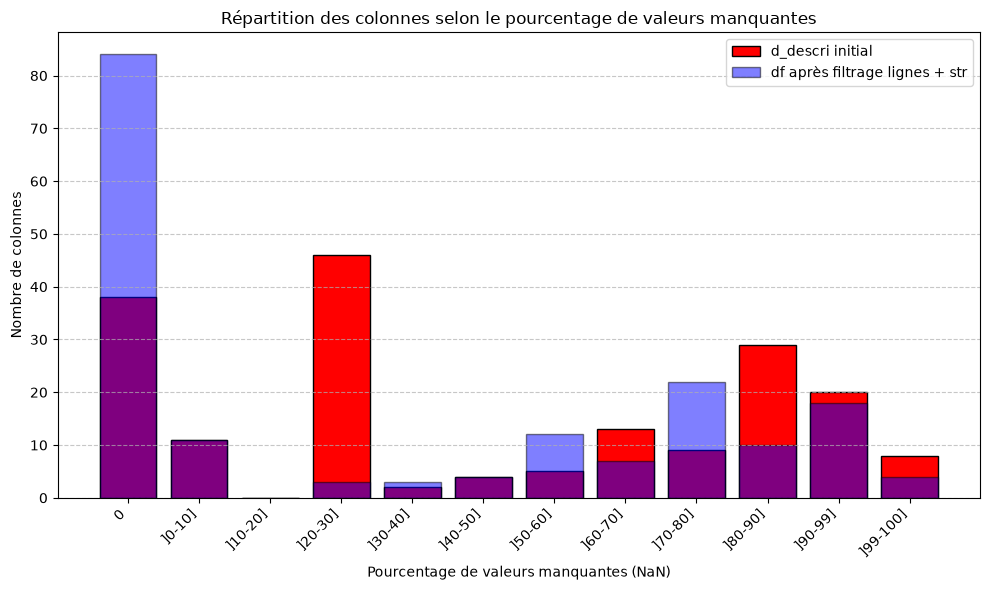

In [102]:
def plot_diff_na(df1, df1_libelle, df2, df2_libelle):
    """Compare la répartition des colonnes selon leur pourcentage de valeurs manquantes."""
    nan_df1 = df1.isna().mean() * 100
    nan_df2 = df2.isna().mean() * 100

    bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
    labels = [
        "0", "]0-10]", "]10-20]", "]20-30]", "]30-40]", "]40-50]",
        "]50-60]", "]60-70]", "]70-80]", "]80-90]", "]90-99]", "]99-100]"
    ]

    x = np.arange(len(labels))
    plt.figure(figsize=(10, 6))

    for k in range(2):
        counts_df = pd.cut(
            nan_df2 if k == 1 else nan_df1, bins=bins, labels=labels, include_lowest=True
        ).value_counts(sort=False)
        plt.bar(
            x, counts_df.values,
            color="blue" if k == 1 else "red", alpha=1-k*0.5,
            edgecolor="black", label=df2_libelle if k == 1 else df1_libelle
        )

    plt.title("Répartition des colonnes selon le pourcentage de valeurs manquantes")
    plt.xlabel("Pourcentage de valeurs manquantes (NaN)")
    plt.ylabel("Nombre de colonnes")
    plt.xticks(x, labels, rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_diff_na(d_descri, "d_descri initial", df, "df après filtrage lignes + str")

**Affichage graphique du nombre d'individus par classe**

tage_PS_mois  1.0  2.0  3.0  NaN
tage_PS                         
1              59    0    0    0
2              32   44   50   33


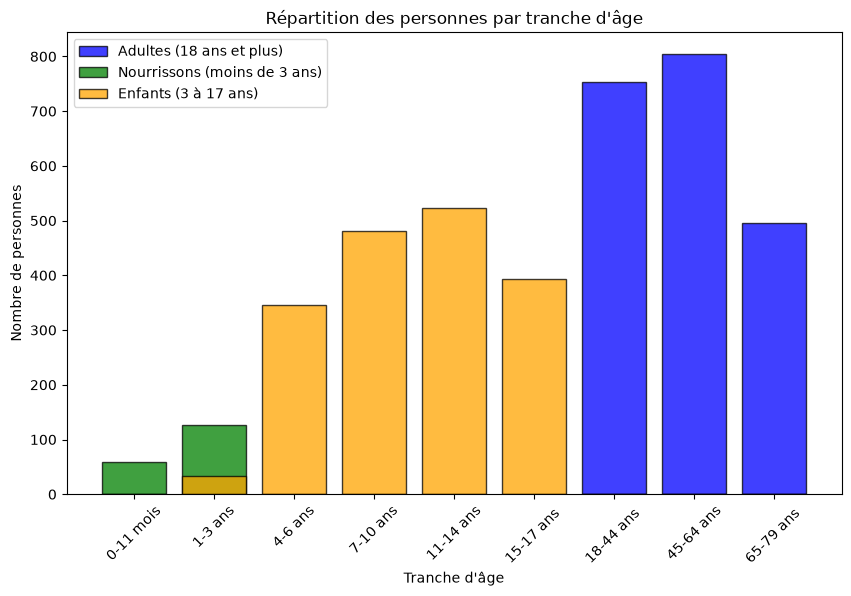

In [103]:
def sep_age(dataframe, forme_return="liste"):
    '''
    Sépare le dataframe en trois sous-dataframes selon l'âge : adultes, nourrissons et enfants.
    Peut rentre 3 sous-dataframes ou un dictionnaire de dataframes selon le paramètre forme_return.
    '''
    df_adulte = dataframe[dataframe["tage_PS"] >= 7]
    df_nourisson = dataframe[dataframe["tage_PS_mois"].notna()]
    df_enfant = dataframe[(dataframe["tage_PS_mois"].isna()) & (dataframe["tage_PS"] < 7)]

    if forme_return == "liste":
        return df_adulte, df_nourisson, df_enfant

    elif forme_return == "dict":
        df_age = {
        "Adultes": df_adulte,
        "Enfants": df_enfant,
        "Nourrissons": df_nourisson
    }
        return df_age

    else:
        raise ValueError("Le paramètre 'forme_return' doit être soit 'liste' soit 'dict'.")

tableau_croise = pd.crosstab(
    df.loc[df["tage_PS"].isin([1, 2]), "tage_PS"],
    df.loc[df["tage_PS"].isin([1, 2]), "tage_PS_mois"],
    dropna=False
)
print(tableau_croise) # On a donc33 enfants de 36 mois

df_adulte, df_nourisson, df_enfant = sep_age(df, forme_return="liste")

bins = [0,1,2,3,4,5,6,7,8,9]
labels = ['0-11 mois', '1-3 ans', '4-6 ans', '7-10 ans', '11-14 ans', '15-17 ans ', '18-44 ans ', '45-64 ans', '65-79 ans ']

counts_adulte = pd.cut(df_adulte["tage_PS"], bins=bins, labels=labels)
counts_nourisson = pd.cut(df_nourisson["tage_PS"], bins=bins, labels=labels)
counts_enfant = pd.cut(df_enfant["tage_PS"], bins=bins, labels=labels)

x = np.arange(len(labels))

plt.figure(figsize=(10, 6))
plt.bar(x, counts_adulte.value_counts(sort=False), color='blue', alpha=0.75, edgecolor='black', label='Adultes (18 ans et plus)')
plt.bar(x, counts_nourisson.value_counts(sort=False), color='green', alpha=0.75, edgecolor='black', label='Nourrissons (moins de 3 ans)')
plt.bar(x, counts_enfant.value_counts(sort=False), color='orange', alpha=0.75, edgecolor='black', label='Enfants (3 à 17 ans)')
plt.xlabel('Tranche d\'âge')
plt.ylabel('Nombre de personnes')
plt.title('Répartition des personnes par tranche d\'âge')
plt.xticks(x, labels, rotation=45)
plt.legend()
plt.show()


**Regler le problèmes des valeurs manquantes :**  
- Colonnes vides = suppression
- très peu de valeurs manquantes (<1% par exemple) = suppresion ligne
- bcp valeur manquantes : verification si c'est pas juste un 0 non encodé, ou resoudre le prbl. Si pas possible = ecarter la colonne
- Valeurs manquantes = "Non applicable" : la valeur manquante ne signifie pas un oublie ou un non, par exemple si on a repondu être un homme, il est logique qu'il n'y ai rien dans enceinte, répondre "non" est une information innatendue. Il faut imputer "non applicable"

In [104]:
def supp_col_vides(dataframe):
    '''
    supprime les colonnes vides (toutes les valeurs sont NaN ou NA_APPL) du dataframe.
    '''
    colonnes_vides = dataframe.columns[(dataframe.isna() | dataframe.eq(NA_APPL)).all()]
    return dataframe.drop(columns=colonnes_vides)

def afficher_info_colonnes(dataframe, sep=False):
    '''
    Affiche les informations sur les colonnes contenant des valeurs manquantes,
    triées par pourcentage de valeurs manquantes décroissant.
    Info regroupées par tranche d'âge si sep=True, sinon sur l'ensemble du dataframe.
    '''
    if sep:
        dfs = sep_age(dataframe, forme_return="dict")
    else:
        dfs = {"Données": dataframe}

    for nom, data in dfs.items():
        data = data.copy()

        colonnes_vides = data.columns[(data.isna() | data.eq(NA_APPL)).all()]
        data = data.drop(columns=colonnes_vides)

        infos = []
        for colonne in data.columns:
            nb_na = data[colonne].isna().sum()
            if nb_na > 0:
                infos.append({
                    "colonne": colonne,
                    "valeurs_uniques": data[colonne].nunique(),
                    "nb_na": nb_na,
                    "pct_na": nb_na / len(data) * 100
                })

        infos = sorted(infos, key=lambda x: x["pct_na"], reverse=True)

        print(f"--- {nom} ---")
        print(f"{len(colonnes_vides)} colonne(s) vide(s) à supprimer")

        for info in infos:
            print(
                f"Colonne '{info['colonne']}' : "
                f"{info['valeurs_uniques']} valeurs uniques, "
                f"{info['pct_na']:.2f}% de valeurs manquantes"
            )
        print()

def plot_missing_values_distribution(dataframe, sep=False):
    '''
    sep : bool - définir si on veut séparer entre les âges ou non.
    Si on sépare par âge, on supprime les colonnes vides pour chaque sous-table. Sinon, on ne supprime que les colonnes vides de la table entière.
    '''
    if sep:
        df_adulte, df_nourisson, df_enfant = sep_age(dataframe)
        dfs = {
            "Adultes": df_adulte,
            "Enfants": df_enfant,
            "Nourrissons": df_nourisson
        }

    else:
        dfs = {"Données": dataframe}

    for nom, data in dfs.items():
        # Supprimer les colonnes vides (na ou NA_APPL dans toute la colonne)
        data = supp_col_vides(data)
        
    # Pourcentage de valeurs manquantes par colonne
    bins = [-0.01, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 99, 100.01]
    labels = [
        "0", "]0-10]", "]10-20]", "]20-30]", "]30-40]", "]40-50]",
        "]50-60]", "]60-70]", "]70-80]", "]80-90]", "]90-99]", "]99-100]"
    ]

    comptages = {}

    for nom, data in dfs.items():
        pourcentage_nan = data.isna().mean() * 100
        classes_nan = pd.cut(
            pourcentage_nan,
            bins=bins,
            labels=labels,
            include_lowest=True
        )
        comptages[nom] = classes_nan.value_counts(sort=False)

    x = np.arange(len(labels))
    largeur = 0.25

    plt.figure(figsize=(12, 6))

    for k in range(len(comptages)):
        plt.bar(
            x + (k - 1) * largeur, comptages[list(comptages.keys())[k]],
            width=largeur, alpha=0.75, label=list(comptages.keys())[k]
        )

    plt.title("Nombre de colonnes selon leur pourcentage de valeurs manquantes")
    plt.xlabel("Pourcentage de valeurs manquantes")
    plt.ylabel("Nombre de colonnes")
    plt.xticks(x, labels, rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.7)
    plt.legend()
    plt.tight_layout()
    plt.show()



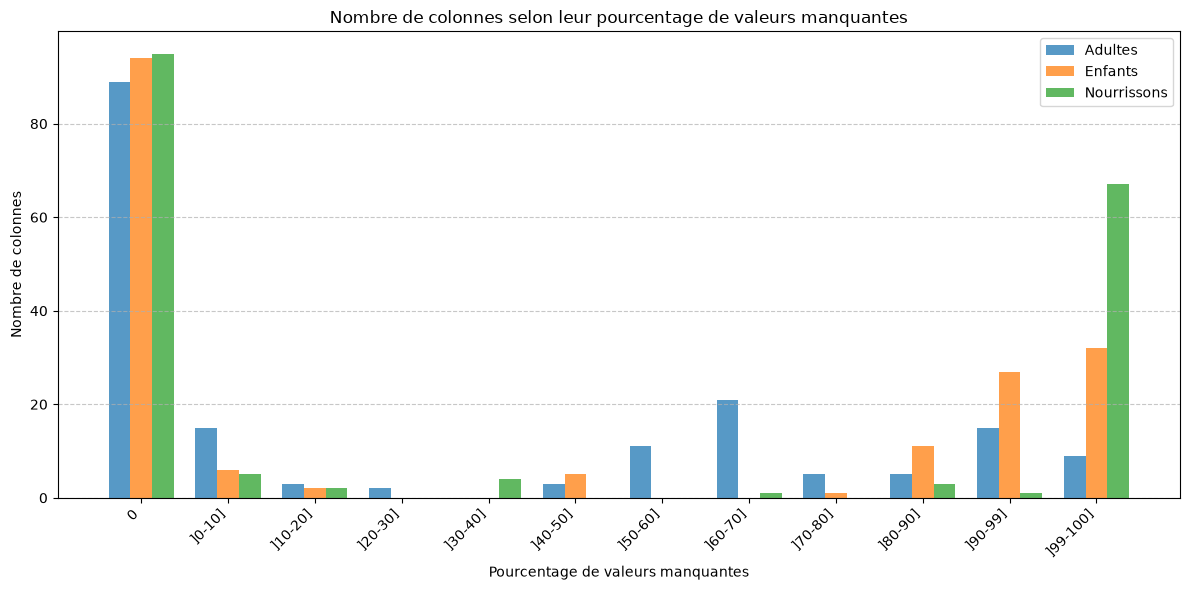

In [105]:
dfs = sep_age(df, forme_return="dict")
# afficher_info_colonnes(df, sep=True)
plot_missing_values_distribution(df, sep=True)

### Comment coder « non applicable » dans une colonne numérique

On a beaucoup de cases vide dans le .csv, mais qui veulent dire "non applicables". Ce sont des valeurs manquantes mais pas par défaut de réponse, juste parce que la question n'avait pas de sens et n'a pas été posée. Par exemple on ne demande pas a un nourisson s'il fume.  
On ne peut pas mettre une chaîne de caractères dans une colonne `int`/`float` : elle passerait en `object` et on perdrait moyennes, régressions, histogrammes... La solution est une **valeur sentinelle numérique** : `NA_APPL = -1`.
- aucune colonne du jeu de données ne contient de valeur négative $\to$ aucune confusion possible avec une vraie réponse (0 reste « Non » / « aucun »)
- `NaN` ne veut plus dire que **« vraie valeur manquante »**, c'est exactement ce qu'on imputera plus tard (moyenne / régression) s'il y a lieu  
- le masque des cases non applicables s'obtient quand on veut avec `df.eq(NA_APPL)`

Pour choisir entre les trois cas :

|situation|exemple|on met|
|---|---|---|
|la réponse est logiquement certaine|femme ménopausée $\to$ pas enceinte ; jamais fumé $\to$ 0 cigarette|la valeur déduite (0, Non...)|
|la question n'a pas de sens ou n'a pas été posée|homme $\to$ grossesse ; enfant de 6 ans $\to$ tabac|`NA_APPL`|
|la question était applicable mais pas de réponse|adulte qui ne donne pas son poids maximum|on laisse `NaN`|

⚠️ Avant une moyenne, une régression ou un `describe()`, il faut repasser les `-1` en `NaN` avec `sans_non_applicable(df)`, sinon ils faussent les calculs.

In [106]:
num = df.select_dtypes(include="number")
assert not (num < 0).any().any(), "Il y a déjà des valeurs négatives : choisir un autre code"

def remplir(data, masque, colonnes, valeur):
    '''Écrit `valeur` dans `colonnes` pour les lignes de `masque`, UNIQUEMENT là où la case est vide (NaN).
    On n'écrase donc jamais une vraie réponse.'''
    colonnes = [colonnes] if isinstance(colonnes, str) else list(colonnes)
    for col in colonnes:
        data.loc[masque & data[col].isna(), col] = valeur

def connue(serie):
    '''Vrai là où on a une vraie valeur (ni NaN, ni non applicable)'''
    return serie.notna() & serie.ne(NA_APPL)

def sans_non_applicable(data):
    '''Copie avec NaN à la place de NA_APPL : à utiliser pour moyennes, régressions, imputations'''
    return data.mask(data.eq(NA_APPL))

def bilan_na(avant, apres):
    '''Tableau NaN avant / NaN après / non applicable, colonne par colonne'''
    t = pd.DataFrame({
        "NaN_avant": avant.isna().sum(),
        "NaN_apres": apres.isna().sum(),
        "non_applicable": apres.eq(NA_APPL).sum(),
    })
    t["valeur retrouvée"] = t["NaN_avant"] - t["NaN_apres"] - t["non_applicable"]
    t["NaN_diff"] = t["NaN_avant"] - t["NaN_apres"]
    return t

### Colonnes ou on remplace nan par 0 :
1. Le tabagisme : six quantités  

|format_fume|signification|  
|---|---|  
|1|Oui, quotidiennement|  
|2|Oui, occasionnellement|  
|3|Non, mais a déjà fumé|  
|4|Non, jamais fumé|  

- donc si `fume` vaut 3 ou 4, on peut logiquement mettre 0 dans `nb_cigarettes_jour`, `nb_cigarettes_sem`, `nb_cigarettes_nsp `, `nb_cigares_jour`, `nb_cigares_sem`,  `nb_cigares_nsp`, `nb_pipes_jour`, `nb_pipes_sem`, `nb_pipes_nsp`
- Si `fume` vaut 4, on peut mettre $non applicable$ dans `fume_age_debut`, `fume_age_debut_nsp`, `fume_age_arret`, `fume_age_arret_nsp`
- Si `fume` vaut 1 ou 2, et qu'on a :
  - si `nb_*_nsp` == 1, on met `NA_APPL` dans les 6 autres catégories (`*_jour` et `*_sem`)
  - si `nb_*_jour` == nan et `nb_*_sem` == x, on peut `nb_*_jour` = x / 7 (on aura pas des entier)
  - si `nb_*_sem` == nan et `nb_*_jour` == x, on peut `nb_*_sem` = x * 7 (on aura pas des entier)
  - si on a un chiffre dans cigarette, cigares ou pipe mais pas les autres, on met 0 dans les autres catégories

In [107]:
def nettoyer_fume(dataframe, bilan=False):
    '''
    Nettoie les données des colonnes liées aux fumeurs.
    '''
    colonnes_fume = ["NOIND", "fume", "nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp",
                    "nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp",
                    "nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp",
                    "fume_age_debut", "fume_age_debut_nsp", "fume_age_arret", "fume_age_arret_nsp"]

    # (jour, semaine, ne sait pas) pour chaque type de tabac
    groupes = {
        "cigarettes": ["nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigarettes_nsp"],
        "cigares": ["nb_cigares_jour", "nb_cigares_sem", "nb_cigares_nsp"],
        "pipes": ["nb_pipes_jour", "nb_pipes_sem", "nb_pipes_nsp"],
    }

    d_fume = dataframe.loc[:, colonnes_fume].copy()
    autres_colonnes = colonnes_fume[1:]  # tout sauf NOIND
    colonnes_nb = [c for c in autres_colonnes if c.startswith("nb_")]
    colonnes_age = [c for c in autres_colonnes if c.startswith("fume_age_")]
    colonnes_jour = [j for j, _, _ in groupes.values()]
    colonnes_sem = [s for _, s, _ in groupes.values()]

    # 1) Question posée à partir de 11 ans (tage_PS >= 5) -> non applicable en dessous
    remplir(d_fume, dataframe["tage_PS"] < 5, autres_colonnes, NA_APPL)

    # 2) `fume` vide mais consommation renseignée et pas d'âge d'arrêt (2 individus) = fumeur actuel
    #    quotidien si une quantité/jour est renseignée, sinon occasionnel
    conso_jour = d_fume[colonnes_jour].fillna(0).gt(0).any(axis=1)
    conso_sem = d_fume[colonnes_sem].fillna(0).gt(0).any(axis=1)
    pas_arret = d_fume[["fume_age_arret", "fume_age_arret_nsp"]].isna().all(axis=1)
    remplir(d_fume, conso_jour & pas_arret, "fume", 1)
    remplir(d_fume, conso_sem & pas_arret, "fume", 2)

    # 3) Les profils (format_fume : 1 quotidien, 2 occasionnel, 3 ex-fumeur, 4 jamais fumé)
    actuel = d_fume["fume"].isin([1, 2])
    ex_fumeur = d_fume["fume"].eq(3)
    jamais = d_fume["fume"].eq(4)

    # Ex-fumeur ou jamais fumé : consommation actuelle = 0
    # (pour les ex-fumeurs, ça écrase les quantités déclarées pour la période où ils fumaient)
    d_fume.loc[ex_fumeur | jamais, colonnes_nb] = 0

    # Jamais fumé : pas d'âge de début ni d'arrêt -> non applicable
    d_fume.loc[jamais, colonnes_age] = NA_APPL

    # Fumeur actuel : n'a pas arrêté -> âge d'arrêt non applicable
    remplir(d_fume, actuel, ["fume_age_arret", "fume_age_arret_nsp"], NA_APPL)

    # 4) Fumeur actuel : quantités jour <-> semaine, type par type
    for jour, sem, nsp in groupes.values():
        # "ne sait pas" : on ne peut déterminer ni le jour ni la semaine
        d_fume.loc[actuel & d_fume[nsp].eq(1), [jour, sem]] = np.nan

        sait = d_fume[nsp].ne(1)
        mask_jour = actuel & sait & d_fume[jour].isna() & d_fume[sem].notna()
        d_fume.loc[mask_jour, jour] = d_fume.loc[mask_jour, sem] / 7

        mask_sem = actuel & sait & d_fume[sem].isna() & d_fume[jour].notna()
        d_fume.loc[mask_sem, sem] = d_fume.loc[mask_sem, jour] * 7

    # 5) Si un type de tabac est consommé, les autres types passent à 0 (seulement s'ils sont tous vides)
    for source, (jour_s, sem_s, _) in groupes.items():
        consomme = actuel & d_fume[[jour_s, sem_s]].fillna(0).gt(0).any(axis=1)
        for cible, colonnes_cible in groupes.items():
            if cible != source:
                remplir(d_fume, consomme & d_fume[colonnes_cible].isna().all(axis=1), colonnes_cible, 0)

    # 6) "Ne sait pas" = 0 quand la valeur est connue
    for jour, sem, nsp in groupes.values():
        remplir(d_fume, d_fume["fume"].isin([1, 2, 3]) & (connue(d_fume[jour]) | connue(d_fume[sem])), nsp, 0)
    remplir(d_fume, connue(d_fume["fume_age_debut"]), "fume_age_debut_nsp", 0)
    remplir(d_fume, connue(d_fume["fume_age_arret"]), "fume_age_arret_nsp", 0)

    if bilan:
        return d_fume, bilan_na(dataframe[colonnes_fume], d_fume)

    return d_fume

d_fume, bilan_fume = nettoyer_fume(df, bilan=True)
bilan_fume

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
NOIND,0,0,0,0,0
fume,1079,33,1044,2,1046
nb_cigarettes_jour,3098,58,1044,1996,3040
nb_cigarettes_sem,3874,58,1044,2772,3816
nb_cigarettes_nsp,3931,35,1044,2852,3896
nb_cigares_jour,3049,66,1044,1939,2983
nb_cigares_sem,3918,66,1044,2808,3852
nb_cigares_nsp,3939,35,1044,2860,3904
nb_pipes_jour,3075,67,1044,1964,3008
nb_pipes_sem,3930,67,1044,2819,3863


2. Historique des régimes amaigrissants

|regime_passe|signification|  
|---|---|  
|1|Oui|  
|2|Non|  
|3|Ne sait pas|  
|4|Refus|  

- si `regime_passe` == 2, on peut mettre $non-applicable$ dans `regime_nb_2dernann`, `regime_nb_anter2dernann `, `regime_nb_anter2dernann  `, `regime_duree_sem`, `regime_duree_mois`, `regime_duree_nsp`
- transformer toutes les `regime_duree_mois` en `regime_duree_sem`, ou faire *4 /4 pour remplir les cases vides si possible

In [108]:
def nettoyer_regime(dataframe, bilan=False):
    ''' 
    Nettoie les données des colonnes liées aux regimes.
    bilan = True donne en 2nd retrun le pd bilan_na
    '''
    
    colonnes_regime = ["regime_passe", "regime_nb_2dernann", "regime_nb_anter2dernann", "regime_type",
                    "regime_duree_sem", "regime_duree_mois", "regime_duree_nsp"]
    nb_reg = ["regime_nb_2dernann", "regime_nb_anter2dernann"]
    duree = ["regime_duree_sem", "regime_duree_mois", "regime_duree_nsp"]

    d_reg = dataframe.loc[:, colonnes_regime].copy()

    # le code 7 n'existe pas dans la notice (format_regime_nb : 1 à 6) et va avec un regime_type vide -> manquant
    d_reg[nb_reg] = d_reg[nb_reg].replace(7, np.nan)

    # regime_passe n'est posée qu'à partir de 15 ans (tage_PS >= 6) -> non applicable en dessous
    remplir(d_reg, dataframe["tage_PS"] < 6, colonnes_regime, NA_APPL)

    # Jamais fait de régime (regime_passe = 2) : 0 régime ; type et durée n'ont pas de sens
    non = d_reg["regime_passe"].eq(2)
    remplir(d_reg, non, nb_reg, 0)
    remplir(d_reg, non, ["regime_type"] + duree, NA_APPL)

    # Durée : la personne donne soit des semaines, soit des mois -> on remplit l'autre colonne
    SEM_PAR_MOIS = 52 / 12 
    oui = d_reg["regime_passe"].eq(1)

    mask_sem = oui & d_reg["regime_duree_sem"].isna() & d_reg["regime_duree_mois"].notna()
    d_reg.loc[mask_sem, "regime_duree_sem"] = d_reg.loc[mask_sem, "regime_duree_mois"] * SEM_PAR_MOIS

    mask_mois = oui & d_reg["regime_duree_mois"].isna() & d_reg["regime_duree_sem"].notna()
    d_reg.loc[mask_mois, "regime_duree_mois"] = d_reg.loc[mask_mois, "regime_duree_sem"] / SEM_PAR_MOIS

    # "ne sait pas la durée" = 0 quand la durée est connue
    remplir(d_reg, oui & connue(d_reg["regime_duree_sem"]), "regime_duree_nsp", 0)

    if bilan:
        return d_reg, bilan_na(dataframe[colonnes_regime], d_reg)

    return d_reg

d_reg, bilan_reg = nettoyer_regime(df, bilan=True)
bilan_reg

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
regime_passe,1593,26,1567,0,1567
regime_nb_2dernann,3351,131,1567,1653,3220
regime_nb_anter2dernann,3393,193,1567,1633,3200
regime_type,3409,126,3283,0,3283
regime_duree_sem,3924,270,3283,371,3654
regime_duree_mois,3642,270,3283,89,3372
regime_duree_nsp,3868,125,3283,460,3743


3. Poids : tentatives de changement, poids passé, poids max / min

- les questions ne sont pas posées à tous les âges : `poids_modif` et `poids_perception` dès 11 ans (`tage_PS` $\geq$ 5), `poids_anndern` dès 15 ans ($\geq$ 6), `poidsmax`, `poidsmin`, leurs âges et `nb_prise_10kg` pour les adultes seulement ($\geq$ 7) $\to$ $non\ applicable$ en dessous
- `poids_modif` = 3 (a voulu grossir) ou 4 (ne s'est pas préoccupé de son poids) : il n'a forcément pas essayé de perdre / ne pas prendre de poids par l'alimentation, les médicaments... $\to$ 0 dans les 5 colonnes de moyens. Avec 5 (ne sait pas) on ne peut rien déduire, on laisse `NaN`
- `poids_modifalim_*` (quantités modifiées pour chaque aliment) n'est posée que si `poids_modifalim` = 1 $\to$ $non\ applicable$ si `poids_modifalim` = 0
- `*_nsp` = 0 quand la valeur est connue

In [109]:
def nettoyer_poids(dataframe, bilan=False):
    '''
    Nettoie les données des colonnes liées aux poids.
    bilan = True donne en 2nd retrun le pd bilan_na
    '''
    moyens = ["poids_modifalim", "poids_plusAP", "poids_medicaments", "poids_substituts", "poids_chirurgie"]
    qtes = [c for c in dataframe.columns if c.startswith("poids_modifalim_") and not c.endswith("_libelle")]
    adulte_seul = ["poidsmax", "poidsmax_nsp", "age_poidsmax", "age_poidsmax_nsp",
                "poidsmin", "poidsmin_nsp", "age_poidsmin", "age_poidsmin_nsp", "nb_prise_10kg"]
    colonnes_poids = (["poids_anndern", "poids_anndern_nsp", "poids_modif", "poids_perception"]
                    + moyens + qtes + adulte_seul)

    d_poids = dataframe.loc[:, colonnes_poids].copy()
    age = dataframe["tage_PS"]

    # Questions non posées selon l'âge
    remplir(d_poids, age < 5, ["poids_modif", "poids_perception"] + moyens + qtes, NA_APPL)
    remplir(d_poids, age < 6, ["poids_anndern", "poids_anndern_nsp"], NA_APPL)
    remplir(d_poids, age < 7, adulte_seul, NA_APPL)

    # N'a pas essayé de perdre / ne pas prendre de poids -> "Non" pour chaque moyen
    remplir(d_poids, d_poids["poids_modif"].isin([3, 4]), moyens, 0)

    # Quantités modifiées : seulement si a modifié son alimentation
    remplir(d_poids, d_poids["poids_modifalim"].eq(0), qtes, NA_APPL)

    # "ne sait pas" = 0 quand la valeur est connue
    for val in ["poids_anndern", "poidsmax", "age_poidsmax", "poidsmin", "age_poidsmin"]:
        remplir(d_poids, connue(d_poids[val]), val + "_nsp", 0)

    if bilan:
        return d_poids, bilan_na(dataframe[colonnes_poids], d_poids)
    return d_poids

d_poids, bilan_poids = nettoyer_poids(df, bilan=True)
bilan_poids

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
poids_anndern,2019,452,1567,0,1567
poids_anndern_nsp,3634,73,1567,1994,3561
poids_modif,1100,56,1044,0,1044
poids_perception,1069,25,1044,0,1044
poids_modifalim,2786,159,1044,1583,2627
poids_plusAP,2790,163,1044,1583,2627
poids_medicaments,2790,163,1044,1583,2627
poids_substituts,2790,163,1044,1583,2627
poids_chirurgie,2790,163,1044,1583,2627
poids_modifalim_laityaourt,3135,269,2866,0,2866


4. Ménopause, grossesse, allaitement

- hommes $\to$ $non\ applicable$ partout (une grossesse n'a pas de sens, répondre « non » serait une information inattendue)
- `menopause` n'est posée qu'aux femmes de 18 ans et plus ($\geq$ 7), les autres questions dès 15 ans ($\geq$ 6) $\to$ $non\ applicable$ en dessous
- femme ménopausée : la réponse est certaine, elle n'est pas enceinte (`enceinte` = 2), n'allaite pas et n'a pas été enceinte dans l'année (0), c'est bien un « non » et pas un « non applicable »
- `enceinte_nbmois` = 0 si `enceinte` = 2, `allaite_nbsem` = 0 si `allaite` = 0

In [110]:
def nettoyer_femmes(dataframe, bilan=False):
    '''
    Nettoie les données des colonnes liées aux femmes.
    bilan = True donne en 2nd retrun le pd bilan_na
    '''
    colonnes_femmes = ["menopause", "enceinte", "enceinte_nbmois", "allaite", "allaite_nbsem", "enceinte_12dermois"]
    d_fem = dataframe.loc[:, colonnes_femmes].copy()

    remplir(d_fem, dataframe["sex_PS"].eq(1), colonnes_femmes, NA_APPL)          # hommes
    remplir(d_fem, dataframe["tage_PS"] < 7, "menopause", NA_APPL)               # ménopause : 18 ans et +
    remplir(d_fem, dataframe["tage_PS"] < 6, colonnes_femmes[1:], NA_APPL)       # grossesse / allaitement : 15 ans et +

    # Femme ménopausée : certain que non
    menopausee = d_fem["menopause"].eq(1)
    remplir(d_fem, menopausee, "enceinte", 2)                              # 2 = Non (format_ouinonnsp)
    remplir(d_fem, menopausee, ["allaite", "enceinte_12dermois"], 0)      # 0 = Non (format_ouinon)

    # Quantités : 0 si pas enceinte / n'allaite pas
    remplir(d_fem, d_fem["enceinte"].eq(2), "enceinte_nbmois", 0)
    remplir(d_fem, d_fem["allaite"].eq(0), "allaite_nbsem", 0)

    if bilan:
        return d_fem, bilan_na(dataframe[colonnes_femmes], d_fem)
    return d_fem

d_fem, bilan_femmes = nettoyer_femmes(df, bilan=True)
bilan_femmes

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
menopause,2836,15,2821,0,2821
enceinte,3238,21,2621,596,3217
enceinte_nbmois,3998,28,2621,1349,3970
allaite,3239,22,2621,596,3217
allaite_nbsem,4012,37,2621,1354,3975
enceinte_12dermois,3241,24,2621,596,3217


5. Situation professionnelle et lien avec la personne de référence (PR)

- `atrav_interv` (« a déjà exercé une profession ») n'est posée qu'aux personnes sans emploi : si `situ_prof_5cl_interv` = 1 (occupe un emploi) la réponse est forcément Oui. Pareil pour `atrav_PR` avec `PCS_8cl_PR` de 1 à 6 (actifs)
- `trav_nuit_interv` et `trav_nuit_2cl_interv` ne sont posées qu'à ceux qui ont un emploi $\to$ $non\ applicable$ sinon
- `tps_travail_*` (temps plein / partiel) n'est posée qu'à ceux qui ont déjà travaillé $\to$ $non\ applicable$ si `atrav_*` = 2
- `lien_interv_PR` : si l'interviewé est la PR (`interv_PR` = 1), le lien avec lui-même n'a pas de sens $\to$ $non\ applicable$. Idem pour `lien_PS_PR` quand la PS est un adulte
- `lien_PS_PR` pour un enfant dont le parent interviewé est la PR : c'est son enfant (code 2 « Enfant »)

In [111]:
def nettoyer_profession(dataframe, bilan=False):
    '''
    Nettoie les données des colonnes liées aux professions.
    bilan = True donne en 2nd retrun le pd bilan_na
    '''
    colonnes_pro = ["atrav_interv", "trav_nuit_interv", "trav_nuit_2cl_interv", "tps_travail_interv",
                    "atrav_PR", "tps_travail_PR", "lien_interv_PR", "lien_PS_PR"]
    d_pro = dataframe.loc[:, colonnes_pro].copy()

    # Interviewé
    a_un_emploi = dataframe["situ_prof_5cl_interv"].eq(1)
    remplir(d_pro, a_un_emploi, "atrav_interv", 1)                                      # 1 = Oui
    remplir(d_pro, ~a_un_emploi, ["trav_nuit_interv", "trav_nuit_2cl_interv"], NA_APPL)
    remplir(d_pro, d_pro["atrav_interv"].eq(2), "tps_travail_interv", NA_APPL)

    # Personne de référence
    remplir(d_pro, dataframe["PCS_8cl_PR"].between(1, 6), "atrav_PR", 1)
    remplir(d_pro, d_pro["atrav_PR"].eq(2), "tps_travail_PR", NA_APPL)

    # Liens
    interv_est_PR = dataframe["interv_PR"].eq(1)
    adulte = dataframe["tage_PS"] >= 7
    remplir(d_pro, interv_est_PR, "lien_interv_PR", NA_APPL)
    remplir(d_pro, interv_est_PR & adulte, "lien_PS_PR", NA_APPL)
    remplir(d_pro, interv_est_PR & ~adulte & dataframe["lien_rep_enf"].isin([1, 2]), "lien_PS_PR", 2)  # 2 = Enfant

    if bilan:
        return d_pro, bilan_na(dataframe[colonnes_pro], d_pro)
    return d_pro

d_pro, bilan_pro = nettoyer_profession(df, bilan=True)
bilan_pro

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
atrav_interv,2734,0,0,2734,2734
trav_nuit_interv,1279,0,1279,0,1279
trav_nuit_2cl_interv,1279,0,1279,0,1279
tps_travail_interv,113,0,113,0,113
atrav_PR,2912,1,0,2911,2911
tps_travail_PR,44,2,42,0,42
lien_interv_PR,2191,0,2191,0,2191
lien_PS_PR,2191,7,1341,843,2184


6. Autres colonnes

- `intoall_confirm_med` (allergie confirmée par un médecin) n'est posée que si `maladie_allergie_alim` = 1 $\to$ $non\ applicable$ sinon
- `regime_forme` n'est pas posée aux 0-35 mois (`tage_PS_mois` renseigné) $\to$ $non\ applicable$
- `IA_score` n'existe pas quand `IA_statut` = 0 (pas d'insécurité alimentaire, pas de score calculé) $\to$ $non\ applicable$
- `taille` et `poids` sont déjà complets : `taille_m` / `taille_d` (mesurée / déclarée) et `poids_m` / `poids_d` sont vides par construction (une seule des deux est remplie). On les remplace par un indicateur `taille_declaree` / `poids_declare` (1 = déclaré, 0 = mesuré)
- `RUC_4cl` est vide quand `revenu` vaut 14 (ne sait pas) ou 15 (refus) : pas de déduction possible, on laisse `NaN`
- pondérations (`pond_*`), `sousest1` / `sousest3`, `lien_rep_enf`, `tage_PS_mois`, `enf_allaite` : vides selon le groupe d'âge par construction, on ne code pas `-1` (une pondération à -1 serait dangereuse), ils sont retirés des groupes où ils sont vides

In [112]:
def nettoyer_divers(dataframe, bilan=False):
    '''
    Nettoie les données des colonnes diverses.
    bilan = True donne en 2nd retrun le pd bilan_na
    '''
    colonnes_div = ["intoall_confirm_med", "regime_forme", "IA_score"]
    d_div = dataframe.loc[:, colonnes_div].copy()

    remplir(d_div, dataframe["maladie_allergie_alim"].eq(0), "intoall_confirm_med", NA_APPL)
    remplir(d_div, dataframe["tage_PS_mois"].notna(), "regime_forme", NA_APPL)
    remplir(d_div, dataframe["IA_statut"].eq(0), "IA_score", NA_APPL)

    if bilan:
        return d_div, bilan_na(dataframe[colonnes_div], d_div)
    return d_div

d_div, bilan_div = nettoyer_divers(df, bilan=True)
bilan_div

,NaN_avant,NaN_apres,non_applicable,valeur retrouvée,NaN_diff
intoall_confirm_med,3893,22,3871,0,3871
regime_forme,185,0,185,0,185
IA_score,3453,0,3453,0,3453


### Nettoyage du dataset avec les fonctions établies

In [113]:
df = importer_donnees(info=False)  # on reprend le df initial pour ne pas avoir les colonnes nettoyées
df = supp_col_vides(df)  # on supprime les colonnes vides avant de nettoyer les autres
print("NA initial :", df.isna().sum().sum())
df = nettoyer_str(df)

for func in [nettoyer_fume, nettoyer_regime, nettoyer_poids, nettoyer_femmes, nettoyer_profession, nettoyer_divers]:
    d_nett = func(df, bilan=False)
    colonnes = [c for c in d_nett.columns if c != "NOIND"]
    df[colonnes] = d_nett[colonnes]

# Mesuré / déclaré : un indicateur à la place de 4 colonnes presque vides
df["taille"] = np.select([df["taille"].notna(), df["taille_m"].notna(), df["taille_d"].notna()], 
                        [df["taille"], df["taille_m"], df["taille_d"]], 
                        default=np.nan)
df["poids"] = np.select([df["poids"].notna(), df["poids_m"].notna(), df["poids_d"].notna()], 
                        [df["poids"], df["poids_m"], df["poids_d"]], 
                        default=np.nan)
df = df.drop(columns=["taille_m", "taille_d", "poids_m", "poids_d"]).copy()
df = supp_col_vides(df)

print("NA final :",df.isna().sum().sum())

# plot_missing_values_distribution(df, sep=True)

# afficher_info_colonnes(df, sep=True)

NA initial : 273359
NA final : 36623


### Imputation des valeurs manquantes

On construit **deux tables par groupe d'âge** (adultes, enfants, nourrissons) :
- `dfs_na` : on ne remplit que ce qui est certain. Les `NaN` restants sont de vraies absences de réponse (les « ne sait pas » et « refus » sont passés en `NaN`), toutes les lignes sont conservées
- `dfs_imp` : on remplace le plus de `NaN` possible

Étapes pour `dfs_imp`, groupe par groupe :
1. **Colonnes vides** supprimées (que des `NaN` ou des `NA_APPL`)
2. **Peu de `NaN`** : on supprime les lignes concernées. Seuil de colonne = le plus grand parmi 0,5 / 1 / 1,5 / 2 % qui supprime au plus 5 % des lignes du groupe
3. **Trop de `NaN`** (plus de 20 %) : on ne touche pas, la colonne est listée dans `non_imputees`
4. **Entre les deux** : imputation selon le type de colonne

|type|exemples|méthode|
|---|---|---|
|quantitative|`poidsmax`, `fume_age_debut`|régression linéaire si elle explique assez (R² en validation croisée $\geq$ 0,3), sinon médiane. Valeur bornée entre min et max observés, arrondie si la colonne ne contient que des entiers|
|codée ordonnée|`RUC_4cl`, `regime_nb_*`, `diplome_*`|même régression, puis arrondi à la modalité existante la plus proche. Sinon valeur la plus fréquente|
|codée sans ordre ou binaire|`fume`, `menopause`, `poids_modifalim_*`|valeur la plus fréquente|

Ordre pour chaque groupe : les colonnes **« portes »** (`fume`, `regime_passe`, `poids_modif`, `poids_modifalim`, `menopause`, `enceinte`, `allaite`) sont imputées d'abord, puis on **rejoue les règles des `nettoyer_*`** pour que les colonnes dépendantes suivent (ex. `regime_passe` imputé à 2 $\to$ `regime_nb_*` = 0), puis on impute le reste.

Règles importantes :
- on n'impute une colonne que s'il y a au moins 10 valeurs connues (sinon la « médiane » d'une valeur n'a pas de sens)
- **on n'impute que dans la population concernée par la question** : un fumeur sans quantité reçoit la médiane des *fumeurs* (pas celle de tout le monde, pleine de 0). Dictionnaire `POPULATION_APPLICABLE`
- les `NA_APPL` ne sont jamais touchés
- une colonne « jumelle » est calculée à partir de l'autre (`nb_*_sem` = 7 × `nb_*_jour`, `regime_duree_mois` à partir de `regime_duree_sem`) pour rester cohérent
- jamais imputés : pondérations, `fpc*`, `imc`, `statnut` (calculées) et `regime_type` (format faux dans la notice)

In [114]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score

# ---------------------------------------------------------------- paramètres
SEUIL_TROP_NA = 20                  # % de NaN au-delà duquel on ne touche pas à la colonne
SEUILS_LIGNES = [0.5, 1, 1.5, 2]    # seuils de NaN par colonne testés pour supprimer des lignes
PLAFOND_LIGNES = 5                  # % max de lignes supprimées dans un groupe d'âge (donc aussi au total)
R2_MIN = 0.3                        # R² (validation croisée) minimal pour garder la régression
MIN_REGRESSION = 50                 # nombre minimal de valeurs connues pour essayer une régression
MIN_CONNUS = 10                     # en dessous, trop peu de valeurs connues pour imputer quoi que ce soit
PREDICTEURS = ["sex_PS", "tage_PS", "taille", "poids"]   # colonnes complètes utilisées par la régression

# ---------------------------------------------------------------- codes "Ne sait pas" / "Refus" (formats de la notice)
CODES_NSP_REFUS = {
    "diplome_interv": [13, 14],
    "atrav_interv": [3],
    "trav_nuit_interv": [5],
    "PCS_8cl_interv": [9, 10],
    "PCS_4cl_interv": [5],
    "tps_travail_interv": [3],
    "vacances_interv": [3, 4],
    "lien_interv_PR": [12],
    "lien_PS_PR": [12],
    "diplome_PR": [13, 14],
    "atrav_PR": [3],
    "PCS_8cl_PR": [9, 10],
    "PCS_4cl_PR": [5],
    "tps_travail_PR": [3],
    "stat_log_2cl": [3],
    "soins": [3],
    "situ_fin_3cl": [4],
    "revenu": [14, 15],
    "intoall_confirm_med": [3],
    "regime_passe": [3],
    "regime_nb_2dernann": [6],
    "regime_nb_anter2dernann": [6],
    "poids_modif": [5],
    "poids_perception": [4],
    "nb_prise_10kg": [5],
    "menopause": [3],
    "enceinte": [3],
}

# ---------------------------------------------------------------- types de colonnes
# Quantitatives = colonnes sans format dans la notice. Toute colonne non listée est "codée sans ordre".
COLONNES_QUANTITATIVES = [
    "taille", "poids", "IA_score", "regime_duree_sem", "regime_duree_mois", "poids_anndern",
    "poidsmax", "poidsmin", "age_poidsmax", "age_poidsmin", "enceinte_nbmois", "allaite_nbsem",
    "nb_cigarettes_jour", "nb_cigarettes_sem", "nb_cigares_jour", "nb_cigares_sem",
    "nb_pipes_jour", "nb_pipes_sem", "fume_age_debut", "fume_age_arret",
]
COLONNES_ORDINALES = ["revenu", "RUC_4cl", "nb_prise_10kg", "regime_nb_2dernann", "regime_nb_anter2dernann",
                      "diplome_interv", "diplome_PR"]

# Colonnes "portes" : elles décident si les questions suivantes ont un sens (ex. regime_passe -> regime_nb_*)
COLONNES_PORTES = ["fume", "regime_passe", "poids_modif", "poids_modifalim", "menopause", "enceinte", "allaite"]
COLONNES_EXCLUES = ["NOMEN", "NOIND", "zae", "fpc1", "fpc2", "fpc3", "imc", "statnut", "regime_type"]

def est_exclue(col):
    return col in COLONNES_EXCLUES or col.startswith("pond_")

def type_colonne(col):
    if col in COLONNES_QUANTITATIVES:
        return "quantitative"
    if col in COLONNES_ORDINALES:
        return "ordinale"
    return "codée"

# ---------------------------------------------------------------- population concernée par chaque question
# colonne : (colonne "porte", valeurs de la porte pour lesquelles la question est posée)
POPULATION_APPLICABLE = {
    "fume_age_debut": ("fume", [1, 2, 3]), "fume_age_debut_nsp": ("fume", [1, 2, 3]),
    "fume_age_arret": ("fume", [3]), "fume_age_arret_nsp": ("fume", [3]),
    "allaite_nbsem": ("allaite", [1]), "enceinte_nbmois": ("enceinte", [1]),
}
for tabac in ["cigarettes", "cigares", "pipes"]:
    for suffixe in ["jour", "sem", "nsp"]:
        POPULATION_APPLICABLE[f"nb_{tabac}_{suffixe}"] = ("fume", [1, 2])
for col in ["regime_nb_2dernann", "regime_nb_anter2dernann", "regime_duree_sem", "regime_duree_mois", "regime_duree_nsp"]:
    POPULATION_APPLICABLE[col] = ("regime_passe", [1])

def population_applicable(data, col):
    """Masque des lignes pour lesquelles la question `col` a un sens (hors non applicable)."""
    if col.startswith("poids_modifalim_"):
        porte, valeurs = "poids_modifalim", [1]
    elif col in POPULATION_APPLICABLE:
        porte, valeurs = POPULATION_APPLICABLE[col]
    else:
        return data[col].ne(NA_APPL)
    if porte not in data.columns:
        return pd.Series(False, index=data.index)
    return data[porte].isin(valeurs) & data[col].ne(NA_APPL)

# colonne dérivée : (colonne source, facteur)  ->  dérivée = source * facteur
PAIRES_DERIVEES = {
    "nb_cigarettes_sem": ("nb_cigarettes_jour", 7),
    "nb_cigares_sem": ("nb_cigares_jour", 7),
    "nb_pipes_sem": ("nb_pipes_jour", 7),
    "regime_duree_mois": ("regime_duree_sem", 12 / 52),
}

In [115]:
def nsp_refus_en_nan(dataframe):
    """Remplace les codes "Ne sait pas" et "Refus" par NaN (une absence de réponse reste une absence de réponse)."""
    data = dataframe.copy()
    for col, codes in CODES_NSP_REFUS.items():
        if col in data.columns:
            data[col] = data[col].mask(data[col].isin(codes))
    return data

def pourct_na(data):
    return data.isna().mean() * 100

def supprimer_lignes_rares(data):
    """
    Supprime les lignes ayant un NaN dans une colonne presque complète.
    On prend le plus grand seuil de SEUILS_LIGNES qui supprime au plus PLAFOND_LIGNES % des lignes.
    Renvoie (data réduit, infos).
    """
    pct = pourct_na(data)
    choix = {"seuil": 0, "colonnes": [], "pct_lignes": 0.0}
    for seuil in SEUILS_LIGNES:
        colonnes = list(pct[(pct > 0) & (pct <= seuil)].index)
        pct_lignes = data[colonnes].isna().any(axis=1).mean() * 100
        if pct_lignes <= PLAFOND_LIGNES:
            choix = {"seuil": seuil, "colonnes": colonnes, "pct_lignes": pct_lignes}
    masque = data[choix["colonnes"]].isna().any(axis=1)
    return data[~masque].copy(), {**choix, "nb_lignes": int(masque.sum())}

def imputer_colonne(data, col):
    """Impute les NaN de `col` dans `data` (modifié sur place). Renvoie une ligne de journal, ou None."""
    type_col = type_colonne(col)
    pop = population_applicable(data, col)
    cibles = pop & data[col].isna()
    connus = pop & data[col].notna()
    if cibles.sum() == 0 or connus.sum() < MIN_CONNUS:
        return None

    y = data.loc[connus, col]
    valeur = pd.Series(np.nan, index=data.index[cibles])
    methode, r2 = None, np.nan

    # 1) Régression linéaire sur les colonnes complètes (si elle explique assez la colonne)
    if type_col in ("quantitative", "ordinale") and connus.sum() >= MIN_REGRESSION:
        X = data.loc[connus, PREDICTEURS]
        ok = X.notna().all(axis=1)
        if ok.sum() >= MIN_REGRESSION:
            r2 = cross_val_score(LinearRegression(), X[ok], y[ok], cv=5, scoring="r2").mean()
            if r2 >= R2_MIN:
                modele = LinearRegression().fit(X[ok], y[ok])
                Xc = data.loc[cibles, PREDICTEURS]
                okc = Xc.notna().all(axis=1)
                valeur[okc[okc].index] = modele.predict(Xc[okc])
                methode = "régression"

    # 2) Sinon (ou si les prédicteurs manquent) : médiane pour une quantité, valeur la plus fréquente pour un code
    if type_col == "quantitative":
        valeur = valeur.fillna(y.median())
        valeur = valeur.clip(y.min(), y.max())
        if (y % 1 == 0).all():
            valeur = valeur.round()
        methode = methode or "médiane"
    else:
        valeur = valeur.fillna(y.mode().iloc[0])
        if type_col == "ordinale":
            modalites = np.sort(y.unique())
            plus_proche = np.abs(valeur.to_numpy()[:, None] - modalites).argmin(axis=1)
            valeur = pd.Series(modalites[plus_proche], index=valeur.index)
        methode = methode or "plus fréquent"

    data.loc[cibles, col] = valeur
    return {
        "colonne": col, "type": type_col, "methode": methode, "R2_cv": r2,
        "nb_imputes": int(cibles.sum()),
        "moyenne_avant": y.mean() if type_col == "quantitative" else np.nan,
        "moyenne_apres": data.loc[pop, col].mean() if type_col == "quantitative" else np.nan,
    }

FONCTIONS_NETTOYAGE = [nettoyer_fume, nettoyer_regime, nettoyer_poids, nettoyer_femmes, nettoyer_profession, nettoyer_divers]

def propager_nettoyage(data):
    """
    Rejoue les règles des nettoyer_* : une colonne porte qu'on vient d'imputer fixe ses colonnes dépendantes
    (ex. regime_passe imputé à 2 -> regime_nb_* = 0, durées non applicables). Ne remplit que des NaN.
    """
    data = data.copy()
    for fonction in FONCTIONS_NETTOYAGE:
        bloc = fonction(data)
        colonnes = [c for c in bloc.columns if c != "NOIND"]
        data[colonnes] = bloc[colonnes]
    return data

def imputer_groupe(data):
    """
    Impute un groupe d'âge (toutes les colonnes présentes, même vides).
    Phase 1 : colonnes portes, puis on rejoue les règles de déduction.
    Phase 2 : toutes les autres colonnes qui ont entre 0 et SEUIL_TROP_NA % de NaN.
    """
    data = data.copy()
    journal = []

    # Phase 1 : portes
    pct = pourct_na(data)
    portes = [c for c in COLONNES_PORTES if c in data.columns and 0 < pct[c] <= SEUIL_TROP_NA]
    for col in portes:
        ligne = imputer_colonne(data, col)
        if ligne:
            journal.append({"phase": 1, **ligne})
    data = propager_nettoyage(data)

    # Phase 2 : le reste
    pct = pourct_na(data)
    a_imputer = [c for c in pct[(pct > 0) & (pct <= SEUIL_TROP_NA)].index
                 if not est_exclue(c) and c not in PAIRES_DERIVEES]
    for col in a_imputer:
        ligne = imputer_colonne(data, col)
        if ligne:
            journal.append({"phase": 2, **ligne})

    # colonnes jumelles : dérivées de leur colonne source
    for col, (source, facteur) in PAIRES_DERIVEES.items():
        if col in data.columns and source in data.columns:
            masque = data[col].isna() & connue(data[source])
            data.loc[masque, col] = data.loc[masque, source] * facteur
            if masque.any():
                journal.append({"phase": 2, "colonne": col, "type": "quantitative",
                                "methode": f"= {source} x {facteur:.3g}", "R2_cv": np.nan,
                                "nb_imputes": int(masque.sum()), "moyenne_avant": np.nan, "moyenne_apres": np.nan})
    return data, pd.DataFrame(journal)

def construire_tables(dataframe):
    """
    Renvoie (dfs_na, dfs_imp, resume, journal, non_imputees)
    dfs_na  : par groupe d'âge, NaN conservés (sauf ceux qu'on a pu déduire), toutes les lignes
    dfs_imp : par groupe d'âge, lignes rares supprimées puis imputation
    """
    groupes = sep_age(nsp_refus_en_nan(dataframe), forme_return="dict")
    dfs_na, dfs_imp, resume, journaux, non_imputees = {}, {}, [], [], []

    for nom, data in groupes.items():
        dfs_na[nom] = supp_col_vides(data)

        reduite, info = supprimer_lignes_rares(data)

        imp, journal = imputer_groupe(reduite)
        imp = supp_col_vides(imp)
        dfs_imp[nom] = imp
        journal.insert(0, "groupe", nom)
        journaux.append(journal)

        data = dfs_na[nom]
        pct_avant = pourct_na(data)
        for col in imp.columns[imp.isna().any()]:
            if est_exclue(col):
                raison = "exclue de l'imputation"
            elif pct_avant[col] > SEUIL_TROP_NA:
                raison = f"plus de {SEUIL_TROP_NA} % de NaN"
            elif len(journal) and col in set(journal["colonne"]):
                raison = "NaN restants : pas de valeur sûre (porte inconnue ou population)"
            else:
                raison = "trop peu de valeurs connues ou hors population concernée"
            non_imputees.append({"groupe": nom, "colonne": col, "nb_na": int(imp[col].isna().sum()),
                                 "pct_na": round(imp[col].isna().mean() * 100, 1), "raison": raison})

        resume.append({
            "groupe": nom, "lignes": len(data), "seuil_colonne_%": info["seuil"],
            "colonnes_pour_suppression": len(info["colonnes"]),
            "lignes_supprimees": info["nb_lignes"], "lignes_supprimees_%": round(info["pct_lignes"], 1),
            "colonnes_imputees": len(journal), "NaN_dfs_na": int(data.isna().sum().sum()),
            "NaN_dfs_imp": int(imp.isna().sum().sum()),
        })

    return (dfs_na, dfs_imp, pd.DataFrame(resume).set_index("groupe"),
            pd.concat(journaux, ignore_index=True), pd.DataFrame(non_imputees))

Recharcher df (on part du fichier non toucher)
on nettoie les colonnes str
on nettoie toutes les colonnes ou l'on peut logiquement remplacer des na

Puis on prend 2 tables :
- dfs_na : on supprime juste les colonnes vide et on garde tout les NA
- dfs_imp : on impute les na suivant plusieurs règles : On ne touche que aux lignes qui ont <20% NaN (si c'est plus, on considère que l'imputation pourrait mal approximer la réalité)
  - supprimer_lignes_rares :
  - imputer_groupe :
  - supp_col_vides :
### TODO ###

In [116]:
df = importer_donnees(info=False).copy()  # on reprend le df initial pour ne pas avoir les colonnes nettoyées
df = nettoyer_str(df)

for func in [nettoyer_fume, nettoyer_regime, nettoyer_poids, nettoyer_femmes, nettoyer_profession, nettoyer_divers]:
    d_nett = func(df, bilan=False)
    colonnes = [c for c in d_nett.columns if c != "NOIND"]
    df[colonnes] = d_nett[colonnes]

# Mesuré / déclaré : un indicateur à la place de 4 colonnes presque vides
df["taille"] = np.select([df["taille"].notna(), df["taille_m"].notna(), df["taille_d"].notna()], 
                        [df["taille"], df["taille_m"], df["taille_d"]], 
                        default=np.nan)
df["poids"] = np.select([df["poids"].notna(), df["poids_m"].notna(), df["poids_d"].notna()], 
                        [df["poids"], df["poids_m"], df["poids_d"]], 
                        default=np.nan)
df = df.drop(columns=["taille_m", "taille_d", "poids_m", "poids_d"]).copy()
df = supp_col_vides(df)

dfs_na, dfs_imp, resume, journal, non_imputees = construire_tables(df)
resume

,lignes,seuil_colonne_%,colonnes_pour_suppression,lignes_supprimees,lignes_supprimees_%,colonnes_imputees,NaN_dfs_na,NaN_dfs_imp
groupe,,,,,,,,
Adultes,2053,1.5,25,95,4.6,47,7516,501
Enfants,1775,1.0,27,65,3.7,33,3829,21
Nourrissons,185,2.0,7,5,2.7,2,188,161


**Journal de l'imputation** : une ligne par colonne imputée (méthode, R² de la régression, effet sur la moyenne)

In [117]:
journal.round(2)

,groupe,phase,colonne,type,methode,R2_cv,nb_imputes,moyenne_avant,moyenne_apres
0,Adultes,1,regime_passe,codée,plus fréquent,NaN,22,NaN,NaN
1,Adultes,1,poids_modif,codée,plus fréquent,NaN,104,NaN,NaN
2,Adultes,1,poids_modifalim,codée,plus fréquent,NaN,93,NaN,NaN
3,Adultes,1,menopause,codée,plus fréquent,NaN,23,NaN,NaN
4,Adultes,2,revenu,ordinale,plus fréquent,0.00,140,NaN,NaN
...,...,...,...,...,...,...,...,...,...
77,Enfants,2,nb_cigarettes_sem,quantitative,= nb_cigarettes_jour x 7,NaN,6,NaN,NaN
78,Enfants,2,nb_cigares_sem,quantitative,= nb_cigares_jour x 7,NaN,7,NaN,NaN
79,Enfants,2,nb_pipes_sem,quantitative,= nb_pipes_jour x 7,NaN,6,NaN,NaN
80,Nourrissons,2,revenu,ordinale,plus fréquent,-0.13,5,NaN,NaN


**Colonnes qui gardent des `NaN` dans `dfs_imp`** et pourquoi

In [118]:
non_imputees

,groupe,colonne,nb_na,pct_na,raison
0,Adultes,regime_type,72,3.7,exclue de l'imputation
1,Adultes,age_poidsmin,417,21.3,plus de 20 % de NaN
2,Adultes,allaite_nbsem,12,0.6,trop peu de valeurs connues ou hors population...
3,Enfants,regime_nb_anter2dernann,21,1.2,trop peu de valeurs connues ou hors population...
4,Nourrissons,enf_allaite,161,89.4,plus de 20 % de NaN
